# Reading the Denon CIP data

This notebook is a guided tour of the four CIP reports. It describes what is in the files and how the records are organized. It does not calculate savings, score performance, or recommend process changes.

The aim is simple: after reading it, we should be able to follow the same conversation when the CIP team explains the process.

## 1. What did Denon send us?

Each Excel file is a report from one production line. The report header contains the line name, while the filename itself is only a report export name.

In [4]:
from pathlib import Path
import re
import pandas as pd
import matplotlib.pyplot as plt

DATA_DIR = Path('datasets')
REQUIRED = [
    'Date Time', 'Object', 'Recipe', 'Activity', 'Step',
    'Time In Seconds', 'Temp SP', 'Return Temp', 'Supply Flow',
    'Return Flow', 'Min Return Flow SP', 'Return Conducivity',
    'Caustic SP', 'Acid SP', 'Final Rinse Cond. SP', 'Flip'
]

def line_from_report(path):
    raw = pd.read_excel(path, header=None, nrows=10)
    text = ' '.join(raw.astype(str).fillna('').stack())
    match = re.search(r'Line\s*:\s*([^ ]+)', text, flags=re.I)
    return match.group(1) if match else path.stem

def read_report(path):
    # The exported table header is on Excel row 14.
    df = pd.read_excel(path, sheet_name=0, header=13)
    df = df[REQUIRED].copy()
    df['Date Time'] = pd.to_datetime(df['Date Time'], errors='coerce')
    df = df[df['Date Time'].notna()].copy()
    for col in REQUIRED[5:]:
        df[col] = pd.to_numeric(df[col], errors='coerce')
    df['Line'] = line_from_report(path)
    df['Source File'] = path.name
    return df

files = sorted(DATA_DIR.glob('CIP_Log*.xlsx'))
data = pd.concat([read_report(path) for path in files], ignore_index=True)
data = data.sort_values(['Line', 'Object', 'Recipe', 'Date Time']).reset_index(drop=True)
print(f'{len(files)} files loaded, containing {len(data):,} timestamped rows.')
print('Lines in the reports:', ', '.join(sorted(data['Line'].unique())))

4 files loaded, containing 38,943 timestamped rows.
Lines in the reports: M01W01, M01W02, M11W01, M11W02


In [5]:
file_view = (data.groupby(['Line', 'Source File'], as_index=False)
    .agg(rows=('Date Time', 'size'), first_record=('Date Time', 'min'), last_record=('Date Time', 'max')))
file_view

,Line,Source File,rows,first_record,last_record
0,M01W01,CIP_Log-202607261035.xlsx,5742,2026-07-01 10:36:06.703,2026-07-26 09:05:06.653
1,M01W02,CIP_Log-202607261035 (4).xlsx,10290,2026-07-01 22:27:06.703,2026-07-26 03:56:06.703
2,M11W01,CIP_Log-202607261035 (1).xlsx,11539,2026-07-01 16:27:06.703,2026-07-26 09:22:06.653
3,M11W02,CIP_Log-202607261035 (2).xlsx,11372,2026-07-01 16:27:06.703,2026-07-26 09:47:06.653


The four lines represented here are `M01W01`, `M01W02`, `M11W01`, and `M11W02`. The records cover July 2026 in the supplied exports. Each line has a different number of records because the report contains a different number of objects and activities for that line.

## 2. What does one row mean?

A row is a timestamped observation from the CIP station. It tells us what the station was doing at that moment, which object it was cleaning, which activity and step were active, and what the instruments and setpoints reported.

The report is a time series. It is not a list where one row always equals one complete CIP wash.

In [6]:
# One ordinary-looking row, shown horizontally so the fields are easy to read.
sample = data.iloc[[0]].T.rename(columns={data.index[0]: 'Example value'})
sample

,Example value
Date Time,2026-07-25 06:33:06.703000
Object,C01C01-RMT Tank-1
Recipe,Acid
Activity,Pre Rinse
Step,Fill To Tank
Time In Seconds,61
Temp SP,1
Return Temp,37.35
Supply Flow,13200.0
Return Flow,-50.0


### The report's words, in plain English

- `Date Time`: when the observation was recorded.
- `Object`: the tank, pipe route, or piece of equipment being cleaned.
- `Recipe`: the named CIP program or recipe associated with the object.
- `Activity`: the broad phase, such as Pre Rinse, Caustic, Acid, Mid Rinse, Final Rinse, or Final Drain.
- `Step`: the more specific action inside the activity, such as Fill To Tank, Fill Circuit, or Circulation.
- `Time In Seconds`: the controller's elapsed-time value for the running sequence or step.
- `Temp SP`: temperature setpoint. `SP` means setpoint.
- `Return Temp`: measured temperature in the return flow.
- `Supply Flow` and `Return Flow`: flow readings going to and coming back from the equipment. The report labels these as LPH, litres per hour.
- `Min Return Flow SP`: minimum return-flow setpoint.
- `Return Conducivity`: the report's spelling of return conductivity, shown as mS/cm.
- `Caustic SP`, `Acid SP`, and `Final Rinse Cond. SP`: conductivity setpoints shown in mS/cm.
- `Flip`: a 0/1 status field. Its exact control meaning needs to be explained by the PLC or CIP owner.

## 3. How often is the station recording?

Looking at the timestamps tells us how the report behaves as a time series. The next cell shows the gap between consecutive records within each object and recipe.

In [7]:
data['gap_seconds'] = data.groupby(['Line', 'Object', 'Recipe'])['Date Time'].diff().dt.total_seconds()
data['gap_seconds'].describe(percentiles=[.5, .9, .99]).to_frame('Seconds between records')

,Seconds between records
count,3.888400e+04
mean,2.352152e+03
std,2.890351e+04
min,5.995000e+01
50%,6.000000e+01
90%,6.005000e+01
99%,7.382045e+04
max,1.329840e+06


In the supplied files, the normal spacing is about one minute. Longer gaps mean that the same object and recipe were not recorded continuously, or that the report moved between periods of activity.

## 4. What kinds of objects and recipes are present?

This is the vocabulary used by the site. Seeing it first helps us understand what the team means when they refer to a line or an object.

In [8]:
objects = (data.groupby(['Line', 'Object'], as_index=False)
    .agg(records=('Date Time', 'size'), recipes=('Recipe', 'nunique'), activities=('Activity', 'nunique')))
objects

,Line,Object,records,recipes,activities
0,M01W01,C01C01-RMT Tank-1,1087,4,6
1,M01W01,C01C02-RMT Tank-2,1429,4,6
2,M01W01,C01C03-RMT Tank-3,1879,3,6
3,M01W01,C01W03-RMT To Reception line,646,1,4
4,M01W01,R01W01-Milk Reception Line,701,2,4
5,M01W02,M01W02_CC01 - Raw Milk Tanker,10290,1,4
6,M11W01,C01W01-Milk Past-1,2699,2,6
7,M11W01,C02C01-PMT TANK-1,1447,3,6
8,M11W01,C02C02-PMT TANK-2,1515,3,6
9,M11W01,C02C03-PMT TANK-3,1231,2,5


In [9]:
recipe_names = (data[['Line', 'Recipe']]
    .drop_duplicates()
    .sort_values(['Line', 'Recipe']))
recipe_names

,Line,Recipe
0,M01W01,Acid
30,M01W01,Caustic
853,M01W01,Caustic Acid
1081,M01W01,Final rinse
5742,M01W02,Caustic
16032,M11W01,Caustic
18229,M11W01,Caustic Acid
20170,M11W01,Final rinse
27571,M11W02,Caustic
29444,M11W02,Caustic Acid


## 5. What activities and steps appear?

The activity is the large chapter of the cleaning sequence. The step is the sentence inside that chapter. The tables below show how often each name appears in the reports. Counts are record counts, not minutes or litres.

In [10]:
activity_counts = (data.groupby(['Line', 'Activity'], as_index=False)
    .size().rename(columns={'size': 'records'})
    .sort_values(['Line', 'records'], ascending=[True, False]))
activity_counts

,Line,Activity,records
1,M01W01,Caustic,3411
3,M01W01,Final Rinse,1118
5,M01W01,Pre Rinse,839
0,M01W01,Acid,248
4,M01W01,Mid Rinse,95
2,M01W01,Final Drain,31
6,M01W02,Caustic,6523
8,M01W02,Final Rinse,1952
9,M01W02,Pre Rinse,1746
7,M01W02,Final Drain,69


In [11]:
step_names = (data.groupby(['Activity', 'Step'], as_index=False)
    .size().rename(columns={'size': 'records'})
    .sort_values(['Activity', 'records'], ascending=[True, False]))
step_names

,Activity,Step,records
0,Acid,Circulation,1478
3,Acid,Fill To Tank,125
2,Acid,Fill Circuit,115
1,Acid,Empty Tank,31
4,Acid,Front Mix Zone,29
6,Acid,Start Next Activity,2
5,Acid,Heating,1
7,Caustic,Circulation,18413
9,Caustic,Fill Circuit,1240
10,Caustic,Fill To Tank,720


In [12]:
data['Recipe'].unique()

array(['Acid', 'Caustic', 'Caustic Acid', 'Final rinse'], dtype=object)

In plain language, a typical record tells a story like this: an object is selected, the CIP recipe is running, the system is in a broad activity such as Caustic, and the controller is carrying out a smaller step such as Fill Circuit or Circulation. The next timestamp may show the same step again, or it may show that the sequence has moved to the next step.

## 6. Walk through one object

To make the file less abstract, the next cells select the first object and recipe in the data and show its records in time order. Change `LINE_TO_READ`, `OBJECT_TO_READ`, or `RECIPE_TO_READ` if the company wants to explain a different circuit.

In [13]:
LINE_TO_READ = data.loc[0, 'Line']
OBJECT_TO_READ = data.loc[0, 'Object']
RECIPE_TO_READ = data.loc[0, 'Recipe']

example = data[(data['Line'] == LINE_TO_READ) &
               (data['Object'] == OBJECT_TO_READ) &
               (data['Recipe'] == RECIPE_TO_READ)].copy()
example = example.sort_values('Date Time')
print('Line:', LINE_TO_READ)
print('Object:', OBJECT_TO_READ)
print('Recipe:', RECIPE_TO_READ)
print('Records:', len(example))
# example[['Date Time', 'Activity', 'Step', 'Time In Seconds', 'Temp SP', 'Return Temp', 'Supply Flow', 'Return Flow', 'Return Conducivity', 'Flip']].head(30)

Line: M01W01
Object: C01C01-RMT Tank-1
Recipe: Acid
Records: 30


In [14]:
LINE_TO_READ = data.loc[0, 'Line']
OBJECT_TO_READ = data.loc[0, 'Object']

example = data[(data['Line'] == LINE_TO_READ) &
               (data['Object'] == OBJECT_TO_READ)].copy()
example = example.sort_values('Date Time')
print('Line:', LINE_TO_READ)
print('Object:', OBJECT_TO_READ)
print('Records:', len(example))
# example[['Date Time','Recipe', 'Activity', 'Step', 'Time In Seconds', 'Temp SP', 'Return Temp', 'Supply Flow', 'Return Flow', 'Return Conducivity', 'Flip']].head(30)
example.head(50)

Line: M01W01
Object: C01C01-RMT Tank-1
Records: 1087


,Date Time,Object,Recipe,Activity,Step,Time In Seconds,Temp SP,Return Temp,Supply Flow,Return Flow,Min Return Flow SP,Return Conducivity,Caustic SP,Acid SP,Final Rinse Cond. SP,Flip,Line,Source File,gap_seconds
30,2026-07-02 19:38:06.703,C01C01-RMT Tank-1,Caustic,Pre Rinse,Fill To Tank,9,1,41.28750,-62.5000,-50.0,12600,0.902821,55,65,2.0,0.0,M01W01,CIP_Log-202607261035.xlsx,NaN
31,2026-07-02 19:39:06.653,C01C01-RMT Tank-1,Caustic,Pre Rinse,Fill To Tank,69,1,41.22000,12809.3800,11865.0,12600,0.902821,55,65,2.0,0.0,M01W01,CIP_Log-202607261035.xlsx,59.95
32,2026-07-02 19:40:06.703,C01C01-RMT Tank-1,Caustic,Pre Rinse,Fill Circuit,129,1,25.15500,11900.0000,6720.0,12600,1.228840,55,65,2.0,0.0,M01W01,CIP_Log-202607261035.xlsx,60.05
33,2026-07-02 19:41:06.653,C01C01-RMT Tank-1,Caustic,Pre Rinse,Circulation,189,1,25.98750,2003.1250,-1045.0,12600,1.341693,55,65,2.0,1.0,M01W01,CIP_Log-202607261035.xlsx,59.95
34,2026-07-02 19:42:06.703,C01C01-RMT Tank-1,Caustic,Pre Rinse,Circulation,249,1,27.36000,-62.5000,-50.0,12600,1.341693,55,65,2.0,1.0,M01W01,CIP_Log-202607261035.xlsx,60.05
35,2026-07-02 19:43:06.703,C01C01-RMT Tank-1,Caustic,Pre Rinse,Circulation,309,1,27.74250,12778.1300,-50.0,12600,1.341693,55,65,2.0,0.0,M01W01,CIP_Log-202607261035.xlsx,60.00
36,2026-07-02 19:44:06.703,C01C01-RMT Tank-1,Caustic,Caustic,Fill To Tank,369,80,36.22500,12546.8800,30715.0,12600,1.266458,55,65,2.0,0.0,M01W01,CIP_Log-202607261035.xlsx,60.00
37,2026-07-02 19:45:06.703,C01C01-RMT Tank-1,Caustic,Caustic,Fill Circuit,429,80,41.63625,-62.5000,30845.0,12600,6.219436,55,65,2.0,0.0,M01W01,CIP_Log-202607261035.xlsx,60.00
38,2026-07-02 19:46:06.703,C01C01-RMT Tank-1,Caustic,Caustic,Front Mix Zone,489,80,45.59625,11828.1300,3595.0,12600,32.150470,55,65,2.0,0.0,M01W01,CIP_Log-202607261035.xlsx,60.00
39,2026-07-02 19:47:06.653,C01C01-RMT Tank-1,Caustic,Caustic,Circulation,549,80,46.17000,12050.0000,3635.0,12600,36.175550,55,65,2.0,0.0,M01W01,CIP_Log-202607261035.xlsx,59.95


In [15]:
data[data['Object'] == 'C01C01-RMT Tank-1']['Recipe'].unique()

array(['Acid', 'Caustic', 'Caustic Acid', 'Final rinse'], dtype=object)

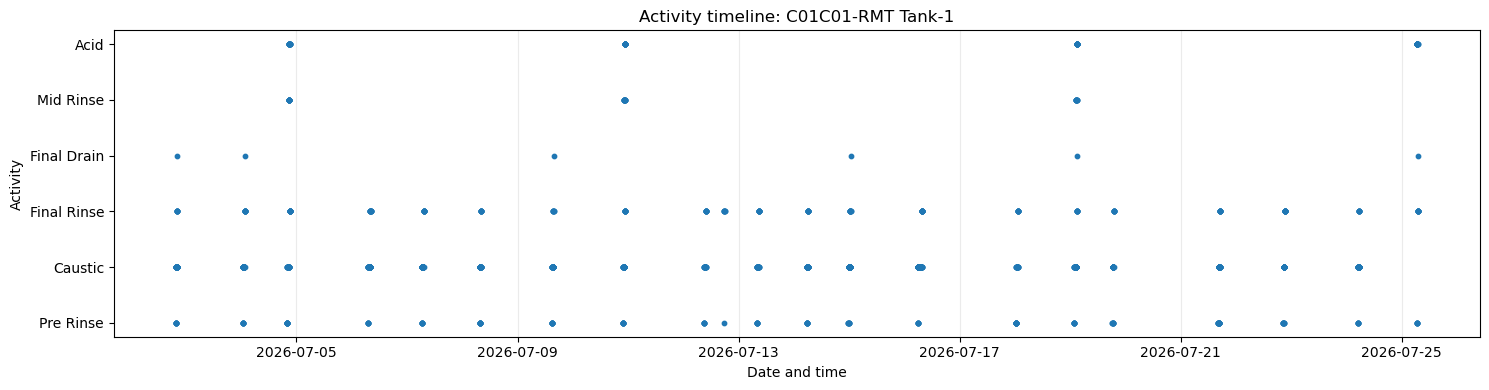

In [16]:
# A simple visual timeline. It shows labels over time; it does not score the process.
fig, ax = plt.subplots(figsize=(15, 4))
activity_order = {name: i for i, name in enumerate(example['Activity'].drop_duplicates())}
y = example['Activity'].map(activity_order)
ax.scatter(example['Date Time'], y, s=10)
ax.set_yticks(list(activity_order.values()), list(activity_order.keys()))
ax.set_title(f'Activity timeline: {OBJECT_TO_READ}')
ax.set_xlabel('Date and time')
ax.set_ylabel('Activity')
ax.grid(axis='x', alpha=.25)
plt.tight_layout()
plt.show()

## 7. What do the measured fields look like?

These are simple ranges from the supplied records. They describe what was recorded, not what the process should have been.

In [17]:
signals = ['Time In Seconds', 'Temp SP', 'Return Temp', 'Supply Flow', 'Return Flow',
           'Min Return Flow SP', 'Return Conducivity', 'Caustic SP', 'Acid SP',
           'Final Rinse Cond. SP', 'Flip']
signal_ranges = data[signals].describe().T[['min', '50%', 'max']].rename(columns={'50%': 'median'})
signal_ranges

,min,median,max
Time In Seconds,2.000000,1365.00000,10000.00
Temp SP,0.000000,80.00000,80.00
Return Temp,0.000000,81.56999,112.95
Supply Flow,-712.500000,12465.63000,51456.25
Return Flow,-1050.000000,11150.00000,51471.88
Min Return Flow SP,4500.000000,12600.00000,25000.00
Return Conducivity,-0.609375,59.19749,205.30
Caustic SP,55.000000,55.00000,55.00
Acid SP,65.000000,65.00000,65.00
Final Rinse Cond. SP,2.000000,2.00000,2.10


The most useful distinction when reading these columns is between a measurement and a setpoint. `Return Temp`, `Supply Flow`, `Return Flow`, and `Return Conducivity` are reported readings. Fields ending in `SP` are targets used by the control system. `Flip` is a status/command field rather than a continuous measurement.

## 8. Questions to keep beside us during the company walkthrough

These are clarification questions about the report's meaning, not process recommendations:

1. Does one `Recipe` represent one complete CIP program, or only the chemical recipe used inside a larger program?
2. What equipment and pipe route does each `Object` name represent?
3. Is `Time In Seconds` elapsed time for the current step, the whole recipe, or another controller timer?
4. What exactly does `Flip = 0` versus `Flip = 1` control?
5. Are the flow values instantaneous PLC readings, averaged values, or values held from another tag?
6. Are `Caustic SP` and `Acid SP` conductivity targets, and what concentration does each target correspond to?
7. Which field tells us that a CIP recipe started and finished?
8. What event or status tells us that the final rinse was accepted and the equipment was released?

## The short version

The files are timestamped CIP station logs. Each record combines an equipment object, a recipe, a broad cleaning activity, a detailed step, controller setpoints, and instrument readings. The report lets us see what the controller recorded over time. The company walkthrough is needed to connect those names and signals to the physical pipes, tanks, valves, chemical concentrations, and release rules.

In [18]:
# Total time for one complete cycle of M11W01_03_C02C01_PMT-1.
TARGET_OBJECT = 'C02C01-PMT TANK-1'
PHASES = ['Pre Rinse', 'Caustic', 'Final Rinse']

obj = data[(data['Line'] == 'M11W01') & (data['Object'] == TARGET_OBJECT)].sort_values('Date Time').copy()
if obj.empty:
    raise ValueError(f'No log rows found for {TARGET_OBJECT} on line M11W01')
obj['Cycle'] = obj['Date Time'].diff().gt(pd.Timedelta(minutes=30)).cumsum()
complete = obj.groupby('Cycle')['Activity'].unique()
if not complete.apply(lambda x: set(PHASES).issubset(x)).any():
    raise ValueError(f'No complete cycle found for {TARGET_OBJECT}')
cycle_id = complete[complete.apply(lambda x: set(PHASES).issubset(x))].index[0]
cycle = obj[obj['Cycle'] == cycle_id]

totals = (cycle[cycle['Activity'].isin(PHASES)]
          .groupby(['Activity', 'Step'])['Time In Seconds'].max()
          .groupby('Activity').sum().div(60)
          .reindex(PHASES)
          .rename('Total time (min)').to_frame())

print(f'Object: M11W01_03_C02C01_PMT-1 ({TARGET_OBJECT})')
print(f'Cycle: {cycle["Date Time"].min()} to {cycle["Date Time"].max()}')
totals.round(2)

Object: M11W01_03_C02C01_PMT-1 (C02C01-PMT TANK-1)
Cycle: 2026-07-01 23:53:06.703000 to 2026-07-02 00:29:06.703000


,Total time (min)
Activity,
Pre Rinse,13.30
Caustic,47.72
Final Rinse,128.32
